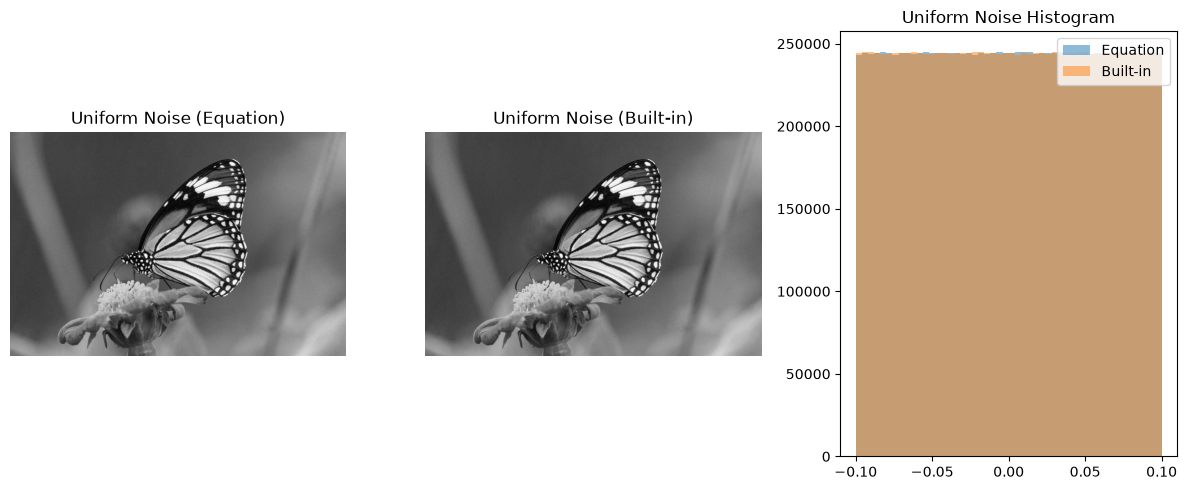

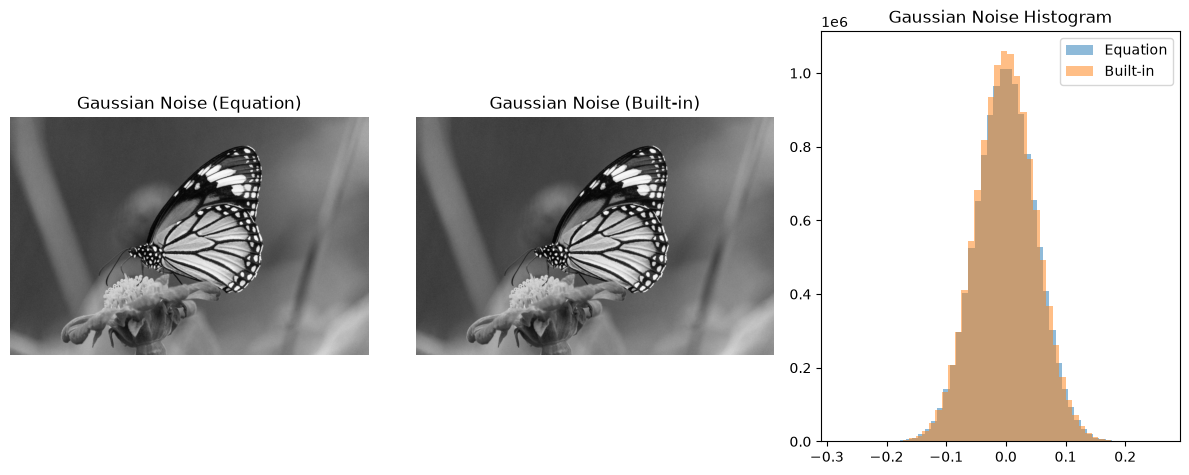

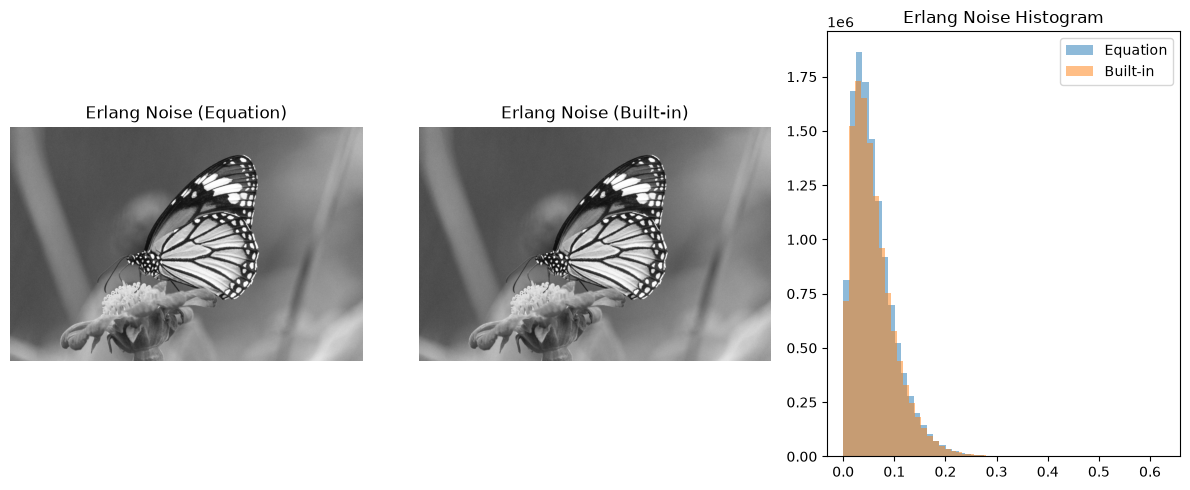

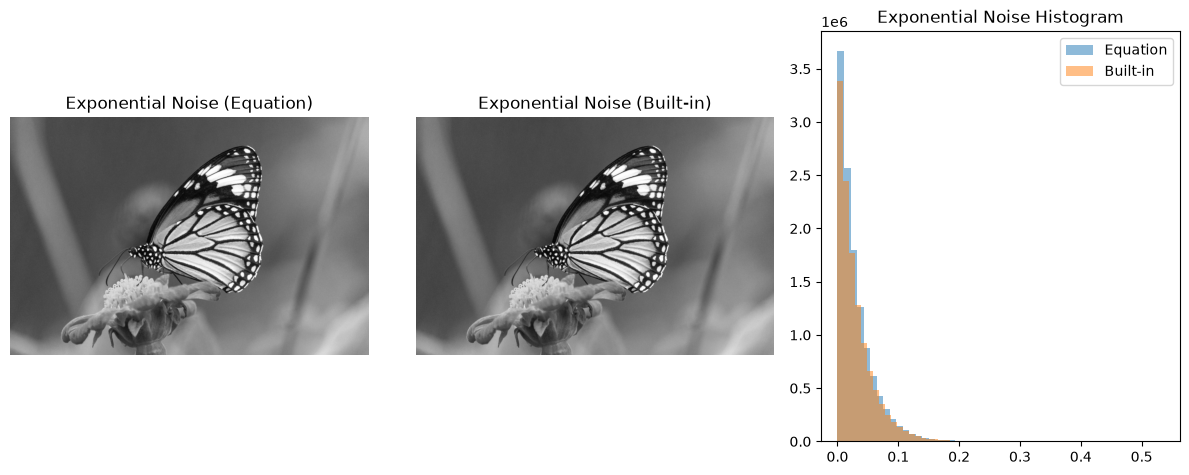

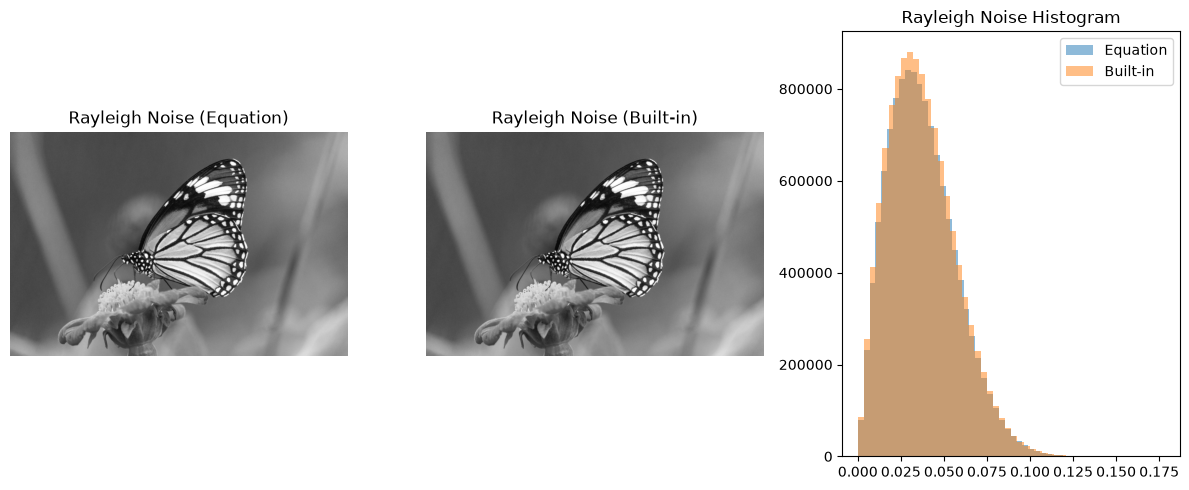

In [1]:
#Write a program to generate following noises using equations derived
#from PDFs of noise distributions. Compare your output with those
#generated using inbuilt function imnoise. Plot the histograms of generated
#noise to determine the shape of the distribution.
#1. Uniform noise
#2. Gaussian noise
#3. Erlang noise
#4. Exponential noise
#5. Rayleigh noise
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("image.jpg", 0)
img = img / 255.0

# Image size
rows, cols = img.shape

# Generate random numbers between 0 and 1
u = np.random.rand(rows, cols)

# 1. Uniform Noise
uniform = -0.1 + (0.2 * u)
uniform_builtin = np.random.uniform(-0.1, 0.1, (rows, cols))

# 2. Gaussian Noise (Box-Muller method)
u1 = np.random.rand(rows, cols)
u2 = np.random.rand(rows, cols)

gaussian = 0.05 * np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
gaussian_builtin = np.random.normal(0, 0.05, (rows, cols))

# 3. Erlang Noise
k = 2
theta = 0.03

erlang = np.zeros((rows, cols))

for i in range(k):
    u = np.random.rand(rows, cols)
    erlang = erlang - theta * np.log(u)

erlang_builtin = np.random.gamma(k, theta, (rows, cols))

# 4. Exponential Noise
u = np.random.rand(rows, cols)

exponential = -0.03 * np.log(1 - u)
exponential_builtin = np.random.exponential(0.03, (rows, cols))

# 5. Rayleigh Noise
u = np.random.rand(rows, cols)
sigma = 0.03

rayleigh = sigma * np.sqrt(-2 * np.log(1 - u))
rayleigh_builtin = np.random.rayleigh(sigma, (rows, cols))


# Store all noise types
noise_list = [
    ("Uniform", uniform, uniform_builtin),
    ("Gaussian", gaussian, gaussian_builtin),
    ("Erlang", erlang, erlang_builtin),
    ("Exponential", exponential, exponential_builtin),
    ("Rayleigh", rayleigh, rayleigh_builtin)
]

# Display results and histograms
for name, noise, builtin in noise_list:

    # Add noise to original image
    noisy1 = np.clip(img + noise, 0, 1)
    noisy2 = np.clip(img + builtin, 0, 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(noisy1, cmap="gray")
    plt.title(name + " Noise (Equation)")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(noisy2, cmap="gray")
    plt.title(name + " Noise (Built-in)")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.hist(noise.flatten(), bins=50, alpha=0.5, label="Equation")
    plt.hist(builtin.flatten(), bins=50, alpha=0.5, label="Built-in")
    plt.title(name + " Noise Histogram")
    plt.legend()

    plt.tight_layout()
    plt.show()